# Supplementary Note 1

This note demonstrates how 'absolute abundance', generated by multiplying relative abundances values from amplicon sequencing by qPCR on the same sample, can place abundances back on an absolute scale while avoiding the constant sum constraint inherent to relative abundance data.  
  
In this notebook, we create a mock community and then demonstrate how relative abundance and 'absolute abundance' are affected by changing the gene copy number ('copies') of amplicon sequencing variants (ASVs).  
  
Relative abundance is computed in the usual way, dividing the number of reads corresponding a specific ASV by the sum of reads across all ASVs.  
  
For simplicity, we are also using the sum of the reads as a proxy for *16S rRNA* qPCR data. In reality, this would be estimated separately but would be expected to mirror this value very closely. Because *16S rRNA* qPCR is affected by gene copy number variation just like amplicon sequencing data, it scales in the exact same way.  
   
 We will be creating a mock community in a table with the following columns:  
   
 **cells**: the actual (but unknowable) number of cells responsible for a given ASV  
 **copies**: the number of gene copies present in the genome  
 **reads**: the number of reads corresponding to a given ASV in an amplicon sequencing dataset  
 **relative_abundance**: the proportion of the total reads corresponding to a given ASV  
 **absolute_abundance**: the relative abundance for a given ASV multiplied by the sum of the reads (which acts as a qPCR proxy in this example)  

### Import libraries

In [1]:
import pandas as pd
import numpy as np

### Start by creating a mock community

In [2]:
cells = [100,1000,20,34,17,1,500,300]
copies = [2,3,4,5,6,7,1,3]
reads = np.multiply(cells, copies)
relative_abundance = [item/sum(reads) for item in reads]
absolute_abundance = [item*sum(reads) for item in relative_abundance]

community = pd.DataFrame(zip(cells,copies,reads,
                             relative_abundance, absolute_abundance),
            columns= ['cells','copies','reads',
                      'relative_abundance', 'absolute_abundance'])

community.index = [f"ASV_{number}" for number in range(1,len(community)+1)]

community

,cells,copies,reads,relative_abundance,absolute_abundance
ASV_1,100,2,200,0.040331,200.0
ASV_2,1000,3,3000,0.604961,3000.0
ASV_3,20,4,80,0.016132,80.0
ASV_4,34,5,170,0.034281,170.0
ASV_5,17,6,102,0.020569,102.0
ASV_6,1,7,7,0.001412,7.0
ASV_7,500,1,500,0.100827,500.0
ASV_8,300,3,900,0.181488,900.0


###  
### What happens if we change the copy number of one abundant community member (ASV_7)?  
###  

In [3]:
cells = [100,1000,20,34,17,1,500,300]
copies = [2,3,4,5,6,7,7,3]
reads = np.multiply(cells, copies)
relative_abundance = [item/sum(reads) for item in reads]
absolute_abundance = [item*sum(reads) for item in relative_abundance]

community = pd.DataFrame(zip(cells,copies,reads,
                             relative_abundance, absolute_abundance),
            columns= ['cells','copies','reads',
                      'relative_abundance', 'absolute_abundance'])

community.index = [f"ASV_{number}" for number in range(1,len(community)+1)]

community

,cells,copies,reads,relative_abundance,absolute_abundance
ASV_1,100,2,200,0.025129,200.0
ASV_2,1000,3,3000,0.376932,3000.0
ASV_3,20,4,80,0.010052,80.0
ASV_4,34,5,170,0.021359,170.0
ASV_5,17,6,102,0.012816,102.0
ASV_6,1,7,7,0.000880,7.0
ASV_7,500,7,3500,0.439754,3500.0
ASV_8,300,3,900,0.113080,900.0


###    
  
We see that the relative abundances change enormously, while the calculated absolute abundances remain constant for all but community member (ASV_7) whose copy number we changed. The relationship between the true number of cells and calculated absolute abundance using qPCR **stays constant**, whereas the relationship between the true number of cells and relative abundance **does not**.

###  
### What happens if we keep the copy number of ASV_7 the same, but change its true number of cells?  
###  

In [4]:
cells = [100,1000,20,34,17,1,1000,300]
copies = [2,3,4,5,6,7,1,3]
reads = np.multiply(cells, copies)
relative_abundance = [item/sum(reads) for item in reads]
absolute_abundance = [item*sum(reads) for item in relative_abundance]

community = pd.DataFrame(zip(cells,copies,reads,
                             relative_abundance, absolute_abundance),
            columns= ['cells','copies','reads',
                      'relative_abundance', 'absolute_abundance'])

community.index = [f"ASV_{number}" for number in range(1,len(community)+1)]

community

,cells,copies,reads,relative_abundance,absolute_abundance
ASV_1,100,2,200,0.036637,200.0
ASV_2,1000,3,3000,0.549551,3000.0
ASV_3,20,4,80,0.014655,80.0
ASV_4,34,5,170,0.031141,170.0
ASV_5,17,6,102,0.018685,102.0
ASV_6,1,7,7,0.001282,7.0
ASV_7,1000,1,1000,0.183184,1000.0
ASV_8,300,3,900,0.164865,900.0


###  
Again we see that the relative abundances of taxa change, even though they still have the same number of cells. In contrast, the estimated absolute abundances remain constant, except for the community member whose abundance we changed.

**It is in this way that the absolute abundance calculation using qPCR data ensures the same number of cells corresponds to the same calculated absolute abundance even when the abundances and copy numbers of all other community members change.**  

<div style="page-break-after: always;"></div>

# Supplementary Note 2

This note demonstrates that *16S rRNA* copy number does not impact estimations of niche breadth or optimum growth temperature for amplicon sequencing variants (ASVs)

In order to demonstrate that the number of *16S rRNA* copies a taxon has does not affect the distribution of its calculated absolute abundances (relative abundance from amplicon sequencing data multiplied by 16S qPCR on the same sample), we can plot the distribution of sequences using different hypothetical 16S copy numbers.

### Import libraries

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

### Plot the distributions of abundances for hypothetical ASVs with different marker gene copy numbers but the same number of reads

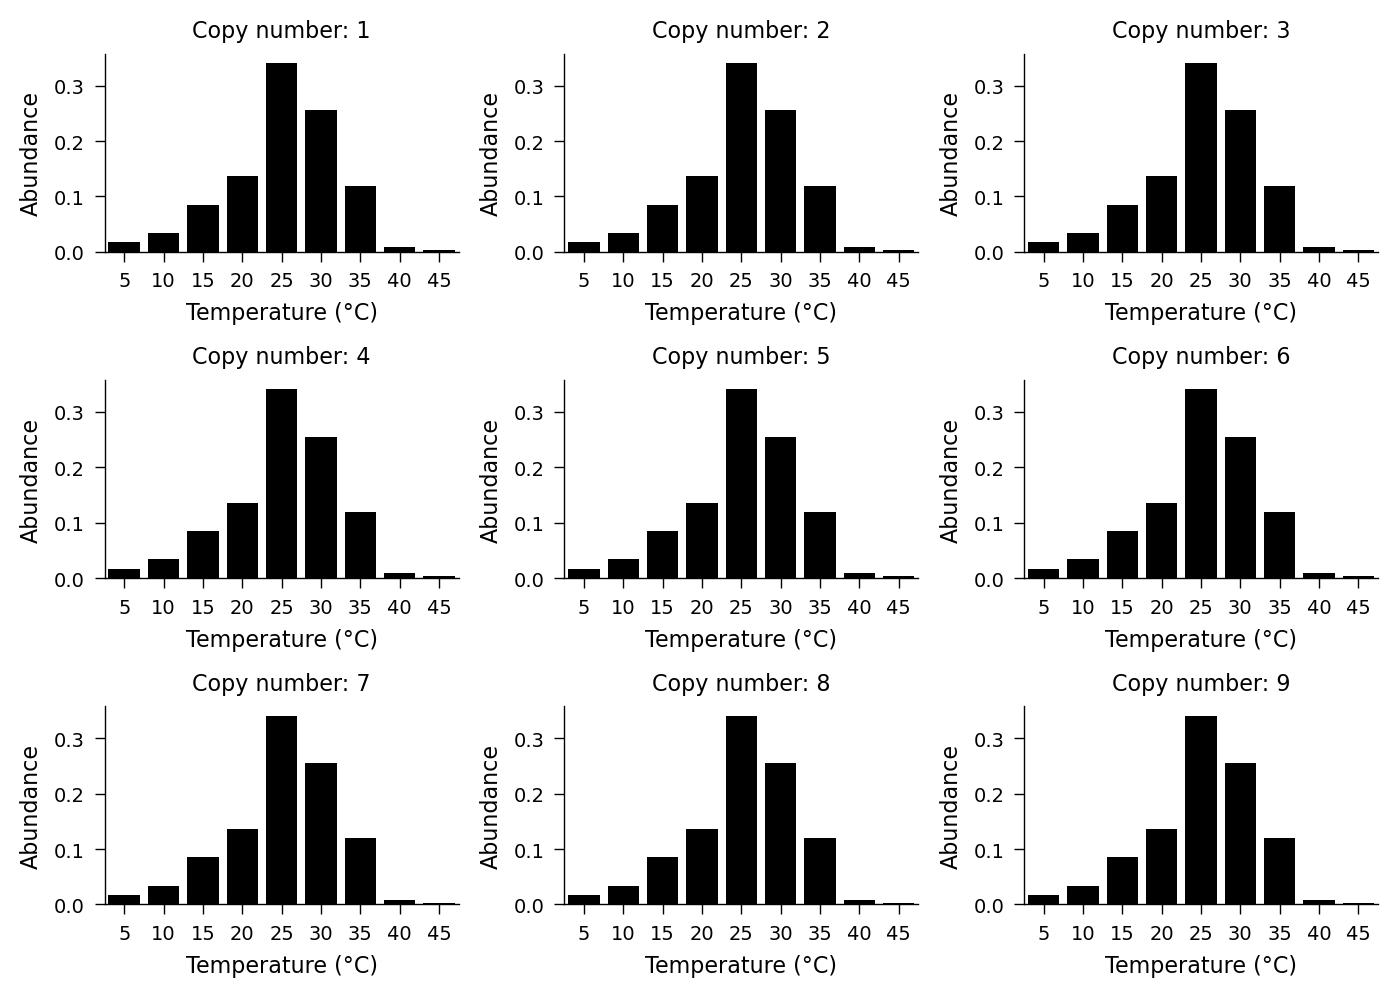

In [6]:
plt.style.use("../Metagenomics/nature.mplstyle")

temps = [5,10,15,20,25,30,35,40,45]
reads = [100,200,500,800,2000,1500,700,50,20]

fig, axes = plt.subplots(ncols= 3, nrows= 3, dpi= 200, figsize= (7,5))
axes = axes.flatten()

for i in [1,2,3,4,5,6,7,8,9]:
    copy_number = i
    abundances = [value * copy_number for value in reads]
    abundances = [value/sum(abundances) for value in abundances]
    df = pd.DataFrame(zip(temps,abundances),
                      columns= ['Temperature (°C)','Abundance'])
    sns.barplot(df, x= 'Temperature (°C)', y= 'Abundance',
                color= 'k', ax= axes[i-1])
    axes[i-1].set_title(f"Copy number: {i}", fontsize= 8)

sns.despine()    
plt.tight_layout()

###  
The distribution of an ASV's calculated absolute abundances remains identical, regardless of how many copies of the gene it has. As a result, estimation of niche breadth (using Levins' measure) or optimum growth temperature (by fitting thermal performance curves) is not biased by copy number variation in multi-copy marker genes so long as the method used to estimate abundance does not create such a bias (see Supplementary Note 1).